In [ ]:
import os

# Select the backend before importing PyRITE; restart to change it.
os.environ.setdefault("PYRITE_MC_BACKEND", "cpu")
import marimo as mo  # noqa: F401
import matplotlib.pyplot as plt

import pyrite

_ = pyrite.fetch_tables()  # Complete installed tables need no download.
tables_ready = True

# From X-rays to detector counts

[![Open in Molab](https://marimo.io/molab-shield.svg)](https://molab.marimo.io/github/Quantum-Light-Matter-Cooperative-QLMC/pyrite/blob/main/docs/notebooks/06-detector-counts.py)

Simulate a 30 keV beam on 100 nm HOPG and acquire an ideal pixel image.
The **16 × 16** pixel panel sits **100 mm** away at **135°**;
**0.01 pC** bunches at **1 MHz** give **10 nA** average current.

In [ ]:
from pyrite import Scene, simulate
from pyrite.beams import Beam, PointBunch, PointSpot
from pyrite.detectors import PixelGrid, PlanarDetector, PlanarPose
from pyrite.geometry import Footprint, Slab
from pyrite.units import ureg

beam = Beam(
    kinetic_energy=30 * ureg.keV,
    transverse=PointSpot(),
    longitudinal=PointBunch(),
    bunch_charge=0.01 * ureg.pC,
    repetition_rate=1 * ureg.MHz,
)
panel = PlanarDetector(
    PlanarPose.from_observation(distance=100 * ureg.mm, polar=135 * ureg.degree),
    pixels=PixelGrid(shape=(16, 16), pitch=ureg.Quantity([1, 1], "mm")),
)
scene = Scene(
    beam,
    Slab(
        "hopg",
        thickness=100 * ureg.nm,
        tilt=30 * ureg.degree,
        footprint=Footprint(width=5 * ureg.mm, height=5 * ureg.mm),
    ),
    panel,
)

## Define the observation

`Scene` defines the geometry; `Observation` specifies response,
exposure and angular sampling. `IdealPhotonCounter` has unit efficiency
and no energy broadening. Count photons in **[0.5, 4) keV** over **1 s**
using a seeded Poisson draw. The **4 × 4** angular tiles are the
source-scoring resolution, not the **16 × 16** detector pixels.

In [ ]:
from pyrite.config import AngularSampling
from pyrite.detectors import IdealPhotonCounter
from pyrite.observations import Acquisition, Observation

acquisition = Acquisition(
    exposure=1 * ureg.s,
    measured_edges=ureg.Quantity([0.5, 4.0], "keV"),
    mode="poisson",
    seed=23,
)
observation = Observation(
    detector="detector",
    response=IdealPhotonCounter(),
    sampling=AngularSampling((4, 4)),
    acquisition=acquisition,
)

In [ ]:
assert tables_ready  # Wait for reference-table installation before transport.
from pyrite.config import CxrReflections, FixedSampling, Numerics

result = simulate(
    scene,
    observation=observation,
    numerics=Numerics(
        sampling=FixedSampling(cxr_electrons=512, brem_electrons=128),
        cxr_reflections=CxrReflections(n_families=2),
    ),
)

In [ ]:
batch = result.acquire(
    region=(slice(None), slice(None)),
    components=("cxr", "brem", "characteristic"),
)
expected_image = batch.expected.sum(axis=-1).reshape(panel.pixels.shape)
count_image = batch.total_counts.reshape(panel.pixels.shape)

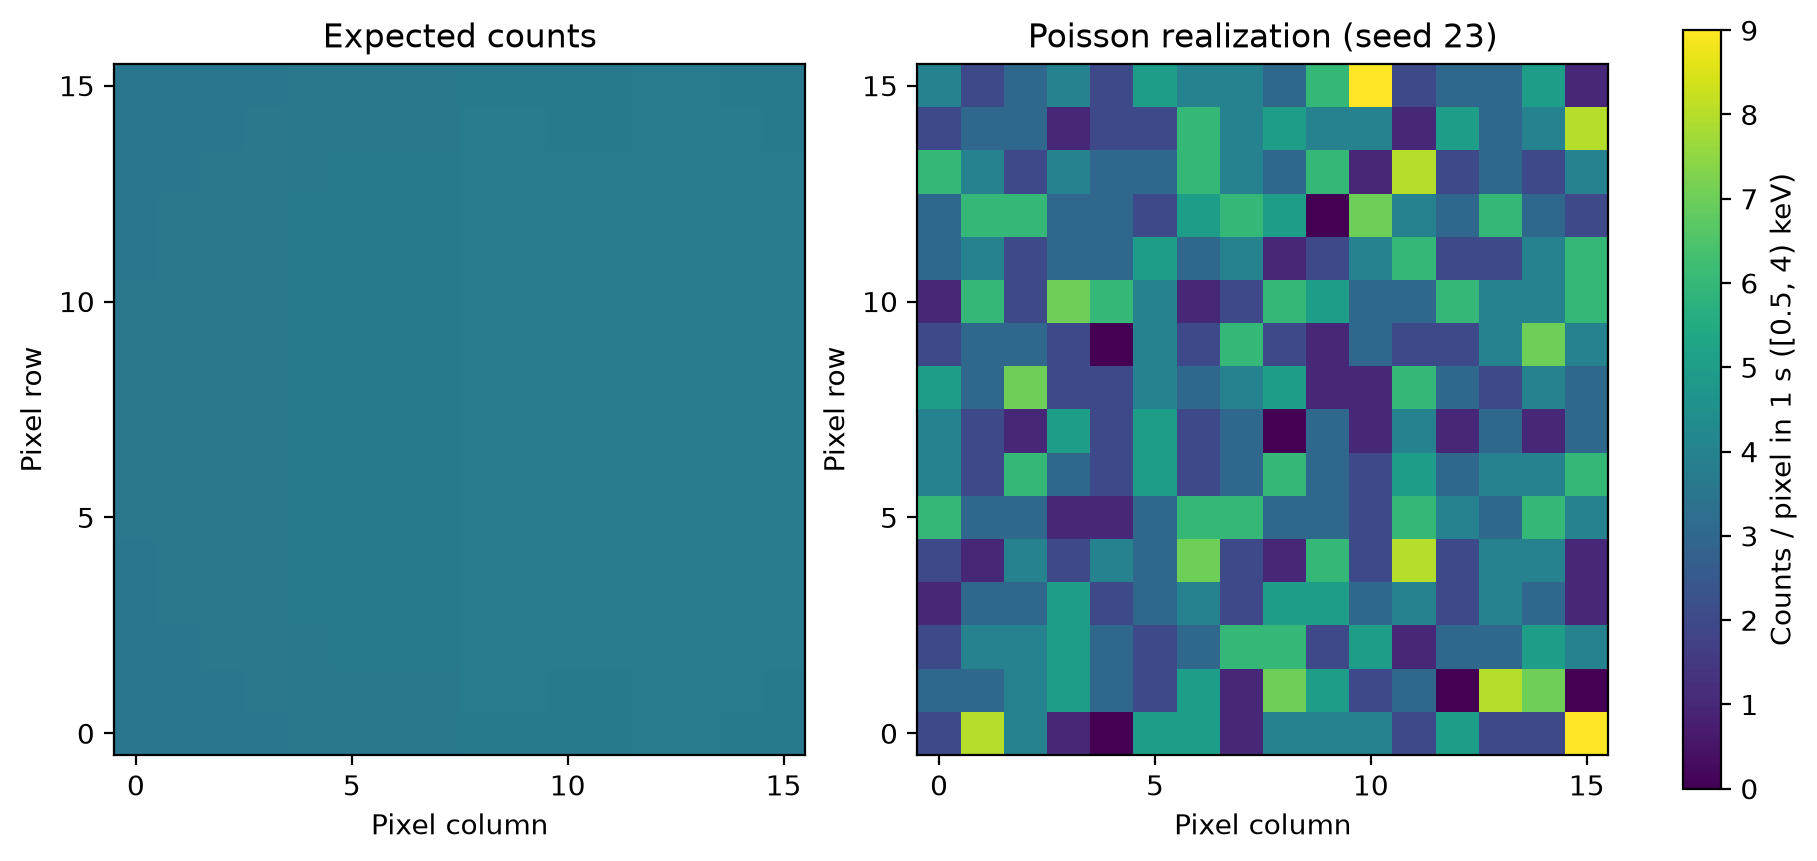

In [ ]:
fig_counts, _axes = plt.subplots(1, 2, figsize=(9, 4.2), layout="constrained")
_maximum = max(float(expected_image.max()), float(count_image.max()))
for _ax, _image, _title in zip(
    _axes,
    (expected_image, count_image),
    ("Expected counts", "Poisson realization (seed 23)"),
    strict=True,
):
    _artist = _ax.imshow(_image, origin="lower", vmin=0, vmax=_maximum)
    _ax.set(xlabel="Pixel column", ylabel="Pixel row", title=_title)
    _ax.set_xticks((0, 5, 10, 15))
    _ax.set_yticks((0, 5, 10, 15))
fig_counts.colorbar(_artist, ax=_axes, label="Counts / pixel in 1 s ([0.5, 4) keV)")
fig_counts  # noqa: B018 - marimo captures the final expression

## Interpretation

Both images already include beam current, exposure, pixel solid angle
and ideal response. **Do not rescale them again.** They include CXR,
bremsstrahlung and characteristic photons within the reporting window;
no downstream filter or background is modeled.

The left panel is an *expected* count image; the right is one Poisson
realization. The shared color scale exposes counting noise, but does not
include Monte Carlo uncertainty or calibration effects.

Try changing only `acquisition.seed`, then doubling `exposure`.
Counts vary with the seed; expectations scale with exposure.
See the [detector how-to](https://pyrite.readthedocs.io/en/latest/guides/detector-observations.html)
and [response physics](https://pyrite.readthedocs.io/en/latest/physics/detectors/detector-response.html).

## Continue learning

Next: [Sampling, convergence and performance](07-sampling-convergence-performance.ipynb).
Use the [detector-observation how-to](../../guides/detector-observations.md)
for an acquisition recipe and the [observations API](../../reference/python-api/observations.md)
for interfaces. [Detector response](../../physics/detectors/detector-response.md)
explains the physical model; [pixel angular interpolation evidence](../../validation/detectors/pixel-angular-interpolation.md)
records checks on pixel reconstruction from angular tiles.

{download}`Download canonical Marimo notebook <../06-detector-counts.py>`